# Route usage — does route choice concentrate across stages?

Every panel reads `output_data/route_usage/` (written by `run-route-usage`); nothing is
refitted here and `mario.scenes` is never opened.

**Unit:** one cell = subject × scene × stage, where the stages are the halves of each
phase by attempt order (early/late discovery, early/late practice).

**Main measure — the Simpson index `D`:** the chance that two *different* attempts in
a cell used the same route. High `D` = concentrated on few routes; `1 / D` = the
effective number of routes. Counting pairs of *different* attempts makes it unbiased at
any cell size, which matters because discovery cells hold far fewer attempts than
practice ones.

**Check measure — Shannon entropy rarefied to 4 attempts** (bits): the expected entropy
of 4 attempts drawn from the cell. Higher = *more varied*, the opposite direction to `D`.

**Model, one per subject (R's lme4):** `y ~ stage + (1 | level) + (1 | level:scene)`,
weighted by cell size (primary) and unweighted. Two resampling checks: a chance level
(route labels shuffled across stages within a scene) and a level bootstrap.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUTPUT_DATA_DIR = Path(os.environ["OUTPUT_DATA_DIR"])
ROUTE_DIR = OUTPUT_DATA_DIR / "route_usage"

sys.path.insert(0, str(Path("__file__").resolve().parent.parent))
from analysis.route_usage import STAGES, CONTRASTS
from analysis.trace_plots import SUBJECT_COLORS

models = json.loads((ROUTE_DIR / "models.json").read_text())
cells = pd.read_csv(ROUTE_DIR / "cells.csv", dtype={"subject": str})
subjects = models["subjects"]
color = {s: SUBJECT_COLORS[i] for i, s in enumerate(sorted(subjects))}
STAGE_LABELS = ["early\ndiscovery", "late\ndiscovery", "early\npractice", "late\npractice"]


def fit(subject, measure="simpson", weighting="n"):
    return next(f for f in models["fits"] if f["subject"] == subject
                and f["measure"] == measure and f["weighting"] == weighting)


plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6})
print(f"{len(cells)} cells over {cells['scene'].nunique()} scenes, subjects {subjects}")

5510 cells over 300 scenes, subjects ['01', '02', '03', '05', '06']


## 1. Stage means per subject

Each subject's model-predicted value per stage for the average scene and level (random
effects at zero), with its 95% Wald CI. Left: the Simpson index turned into the
effective number of routes (`1 / D`; the CI's ends convert directly because `1 / D` is
monotone). Right: rarefied Shannon entropy. Both weighted by cell size. The y-axes are
zoomed to the data.

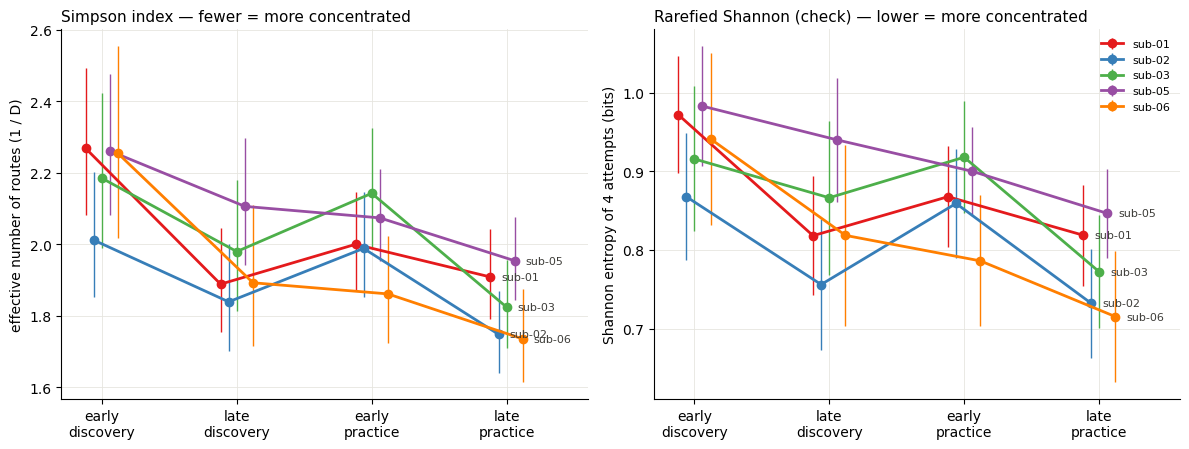

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
x = np.arange(len(STAGES))
for i, s in enumerate(subjects):
    off = (i - (len(subjects) - 1) / 2) * 0.06
    for ax, measure in zip(axes, ["simpson", "shannon_rarefied"]):
        sm = fit(s, measure)["stage_means"]
        if measure == "simpson":
            y = [sm[st]["effective_routes"] for st in STAGES]
            lo = [sm[st]["effective_routes_ci"][0] for st in STAGES]
            hi = [sm[st]["effective_routes_ci"][1] for st in STAGES]
        else:
            y = [sm[st]["est"] for st in STAGES]
            lo = [sm[st]["ci"][0] for st in STAGES]
            hi = [sm[st]["ci"][1] for st in STAGES]
        y, lo, hi = map(np.array, (y, lo, hi))
        ax.errorbar(x + off, y, yerr=[y - lo, hi - y], color=color[s], marker="o", ms=6,
                    lw=2, capsize=0, elinewidth=1, label=f"sub-{s}")
        ax.annotate(f"sub-{s}", (x[-1] + off, y[-1]), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=8, color="#3d3c38")
for ax in axes:
    ax.set_xticks(x, STAGE_LABELS)
    ax.set_xlim(-0.3, len(STAGES) - 0.4)
axes[0].set_ylabel("effective number of routes (1 / D)")
axes[0].set_title("Simpson index — fewer = more concentrated", loc="left", fontsize=11)
axes[1].set_ylabel("Shannon entropy of 4 attempts (bits)")
axes[1].set_title("Rarefied Shannon (check) — lower = more concentrated", loc="left", fontsize=11)
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()
fig.savefig(ROUTE_DIR / "figure_route_usage_stages.png", dpi=150)

## 2. The three contrasts, against chance

One row per subject, on the Simpson index (positive = more concentrated in the later
stage). **Filled dot and thick line:** the weighted fit with its Wald CI.
**Thin line below it:** the level-bootstrap 95% CI (whole levels resampled), which
covers the dependence between a level's scenes. **Hollow dot:** the unweighted fit.
**Grey band:** the chance level — 95% of the contrasts obtained when the route labels
are shuffled across stages within each scene. Its centre sitting at 0 is what shows the
estimator carries no sample-size bias.

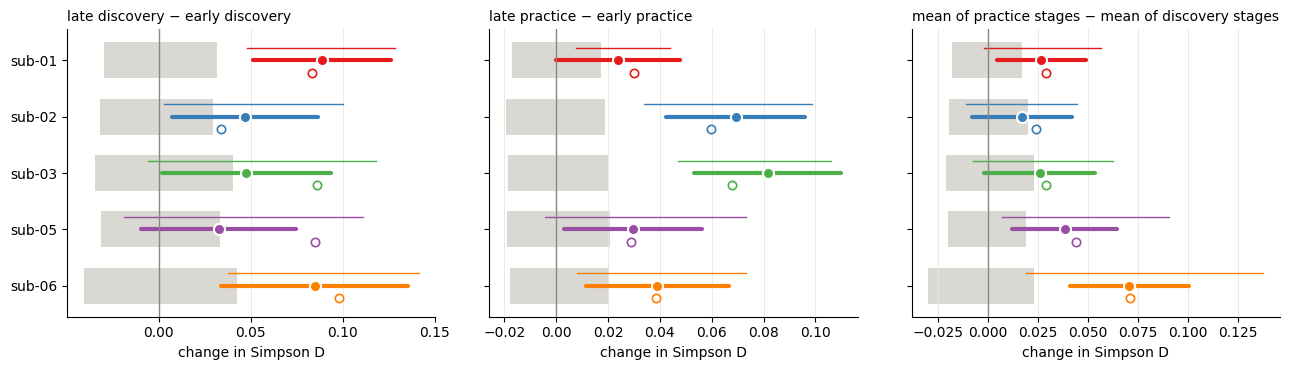

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (name, label) in zip(axes, CONTRASTS.items()):
    for i, s in enumerate(subjects):
        c = fit(s)["contrasts"][name]
        u = fit(s, weighting="none")["contrasts"][name]
        nm, nsd = c["null"]["mean"], c["null"]["sd"]
        ax.fill_betweenx([i - 0.32, i + 0.32], nm - 1.96 * nsd, nm + 1.96 * nsd,
                         color="#d9d8d2", lw=0, zorder=0)
        ax.plot(c["ci"], [i, i], color=color[s], lw=3, solid_capstyle="round")
        ax.plot(c["boot"]["ci"], [i - 0.22, i - 0.22], color=color[s], lw=1)
        ax.plot(c["est"], i, "o", color=color[s], ms=8, mec="white", mew=1.5)
        ax.plot(u["est"], i + 0.22, "o", mfc="none", mec=color[s], ms=6, mew=1.2)
    ax.axvline(0, color="#898781", lw=1)
    ax.set_title(label, loc="left", fontsize=10)
    ax.set_xlabel("change in Simpson D")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(subjects)), [f"sub-{s}" for s in subjects])
axes[0].invert_yaxis()
fig.tight_layout()
fig.savefig(ROUTE_DIR / "figure_route_usage_contrasts.png", dpi=150)

## 3. The numbers

Every contrast for both measures and both weightings. `ci` is the Wald CI, `boot` the
level bootstrap, `p_perm` the permutation p-value against the shuffled labels (its floor
is 1 / (reps + 1)). For Shannon the sign is reversed: negative = more concentrated.

In [4]:
rows = []
for f in models["fits"]:
    for name, c in f["contrasts"].items():
        rows.append({"subject": f["subject"], "measure": f["measure"], "weighting": f["weighting"],
                     "contrast": name, "est": c["est"],
                     "ci": f"[{c['ci'][0]:+.3f}, {c['ci'][1]:+.3f}]", "p": c["p"],
                     "boot": f"[{c['boot']['ci'][0]:+.3f}, {c['boot']['ci'][1]:+.3f}]",
                     "null_mean": c["null"]["mean"], "p_perm": c["null"]["p_perm"]})
table = pd.DataFrame(rows)
with pd.option_context("display.max_rows", 200, "display.width", 160, "display.precision", 4):
    print(table.to_string(index=False))

subject          measure weighting                contrast     est               ci          p             boot   null_mean  p_perm
     01 shannon_rarefied         n late_vs_early_discovery -0.1541 [-0.223, -0.085] 1.2358e-05 [-0.224, -0.072] -3.3194e-04  0.0050
     01 shannon_rarefied         n  late_vs_early_practice -0.0489 [-0.092, -0.006] 2.6104e-02 [-0.087, -0.020]  1.4596e-04  0.0100
     01 shannon_rarefied         n   practice_vs_discovery -0.0519 [-0.093, -0.011] 1.3843e-02 [-0.104, +0.004]  4.1106e-04  0.0050
     01 shannon_rarefied      none late_vs_early_discovery -0.1376 [-0.197, -0.079] 4.7893e-06 [-0.206, -0.071] -1.0620e-03  0.0050
     01 shannon_rarefied      none  late_vs_early_practice -0.0631 [-0.118, -0.008] 2.3791e-02 [-0.102, -0.033]  2.8677e-04  0.0050
     01 shannon_rarefied      none   practice_vs_discovery -0.0581 [-0.099, -0.017] 5.4733e-03 [-0.111, -0.007]  1.0191e-03  0.0050
     01          simpson         n late_vs_early_discovery  0.0887 [+0.051, 